# single-load

In [1]:
%load_ext autoreload
%autoreload 2

%pip install -r requirements.txt
%pip install -e .
%pip install matplotlib

import selfmade.nb101 as nb101
import selfmade.nbcore as nbcore

records = r'.\datas\nasbench_full.tfrecord'
space = nb101.NASBench101Space()
evaluator = nb101.NASBench101Evaluator(records, space)

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python37\python.exe -m pip install --upgrade pip' command.


Obtaining file:///E:/coding/uit_bs/nuro_evo/nb-new
  Attempting uninstall: nasbench
    Found existing installation: nasbench 1.0
    Uninstalling nasbench-1.0:
      Successfully uninstalled nasbench-1.0
  Running setup.py develop for nasbench
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python37\python.exe -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python37\python.exe -m pip install --upgrade pip' command.





Loading dataset from file... This may take a few minutes...
Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`
Loaded dataset in 366 seconds


In [2]:
from sklearn.ensemble import RandomForestRegressor
import secrets
import matplotlib.pyplot as plt
import pandas as pd

# main functions

In [3]:
# Full vanilla (100 evals -> 10 pop, 10 iters)
def vanilla_run(loops, pop):
    pop.evolve_loop(total_gen=loops)
    return pop

In [4]:
# Half vanilla, half guided (100 evals -> 10 pop, 5 val, 5 gui)
def guided_run(loops, pop):
    split = int(loops/2)
    print("Half vanilla")
    pop.evolve_loop(total_gen=split)

    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1)
    fi = nbcore.FeatureImportance(space)
    imp = fi.pipeline(pop.data, rf)

    gui = nbcore.Guidance(space, imp, pop.config)
    gui.sortNsplit()
    gui.calculate_guidance()

    print("Half guided")
    pop.evolve_loop(total_gen=split, guidance = gui)
    return pop

In [5]:
def compare_run(pop : nbcore.Population, loops = 20):
    split = int(loops / 2)
    print("Common half")
    pop.evolve_loop(total_gen = split)
    
    fv_pop = pop.copy()
    sv_pop = pop.copy()
    
    print("Full vanilla")
    fv_pop.evolve_loop(total_gen = split)
    
    
    print("Half guided")
    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1)
    fi = nbcore.FeatureImportance(space)
    for _ in range(split):
        imp = fi.pipeline(sv_pop.data, rf)

        gui = nbcore.Guidance(space, imp, sv_pop.config)
        gui.sortNsplit()
        gui.calculate_guidance()
        sv_pop.guidance = gui
        sv_pop.evolve()
    
    return fv_pop, sv_pop

# test run

In [89]:
pop_size = 100
total_gen = 20
# Set seed và population chung để tạo tính công bằng cho 2 lượt chạy khác nhau
nb101.set_seed(42)
share_pop = nbcore.Population(pop_size, space, evaluator)
share_pop.initialize()
vanilla = share_pop.copy()
guided = share_pop.copy()

Best performance: 0.9458132982254028
Recording generation 0
Finished recording


In [90]:
# fv = guided_run(total_gen, vanilla)
# sv = vanilla_run(total_gen, guided)

fv, sv = compare_run(share_pop)

Common half
Generation 1 - Best performance: 0.9458132982254028
Recording generation 1
Finished recording
Generation 2 - Best performance: 0.9471153616905212
Recording generation 2
Finished recording
Generation 3 - Best performance: 0.9474158883094788
Recording generation 3
Finished recording
Generation 4 - Best performance: 0.9474158883094788
Recording generation 4
Finished recording
Generation 5 - Best performance: 0.9474158883094788
Recording generation 5
Finished recording
Generation 6 - Best performance: 0.9474158883094788
Recording generation 6
Finished recording
Generation 7 - Best performance: 0.9485176205635071
Recording generation 7
Finished recording
Generation 8 - Best performance: 0.9490184187889099
Recording generation 8
Finished recording
Generation 9 - Best performance: 0.9490184187889099
Recording generation 9
Finished recording
Generation 10 - Best performance: 0.9490184187889099
Recording generation 10
Finished recording
Full vanilla
Generation 11 - Best performance:

# plot on vanilla + guided and compare with full vanilla

In [91]:
int_ticks = range(0, total_gen + 1, 2)

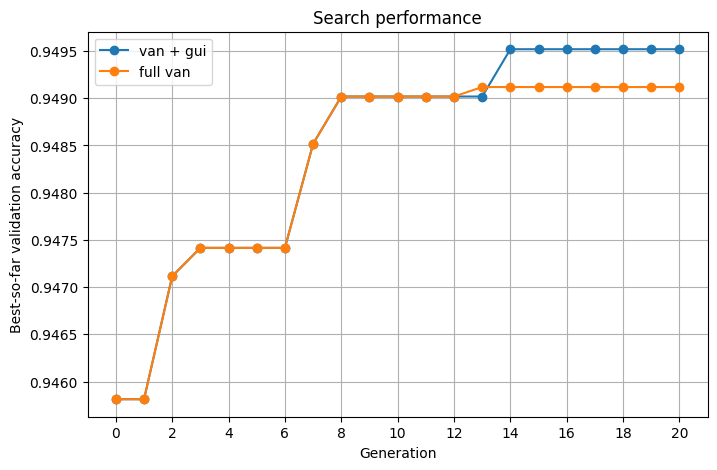

In [92]:
hist = pd.DataFrame(sv.best_history)
hist2 = pd.DataFrame(fv.best_history)

plt.figure(figsize=(8, 5))
plt.plot(
    hist["generation"],
    hist["best_so_far"],
    marker="o"
)

plt.plot(
    hist2["generation"],
    hist2["best_so_far"],
    marker="o"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Best-so-far validation accuracy")
plt.title("Search performance")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

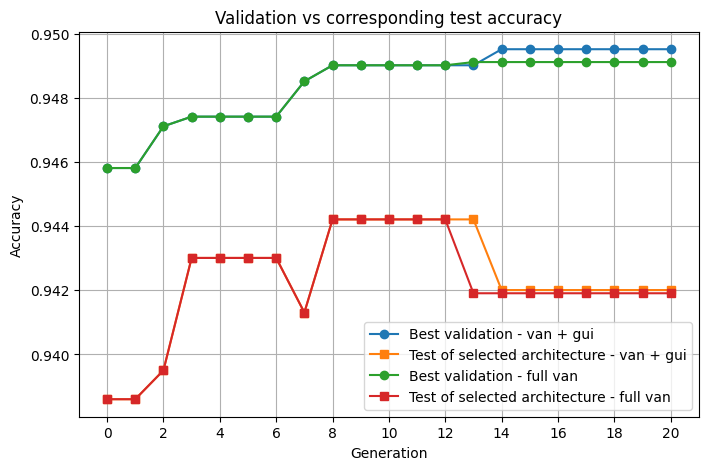

In [93]:
plt.figure(figsize=(8, 5))

plt.plot(
    hist["generation"],
    hist["best_val"],
    marker="o",
    label="Best validation - van + gui"
)

plt.plot(
    hist["generation"],
    hist["best_test"],
    marker="s",
    label="Test of selected architecture - van + gui"
)

plt.plot(
    hist2["generation"],
    hist2["best_val"],
    marker="o",
    label="Best validation - full van"
)

plt.plot(
    hist2["generation"],
    hist2["best_test"],
    marker="s",
    label="Test of selected architecture - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Accuracy")
plt.title("Validation vs corresponding test accuracy")
plt.legend()
plt.grid(True)
plt.show()

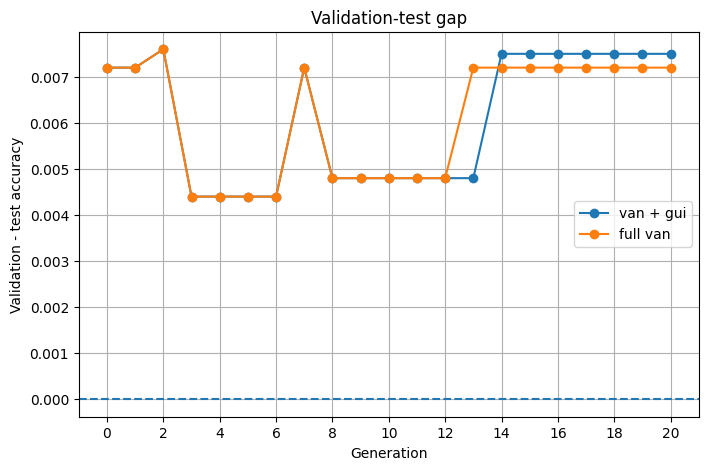

In [94]:
hist["val_test_gap"] = (
    hist["best_val"] - hist["best_test"]
)

hist2["val_test_gap"] = (
    hist2["best_val"] - hist2["best_test"]
)

plt.figure(figsize=(8, 5))
plt.plot(
    hist["generation"],
    hist["val_test_gap"],
    marker="o"
)

plt.plot(
    hist2["generation"],
    hist2["val_test_gap"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Validation - test accuracy")
plt.title("Validation-test gap")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

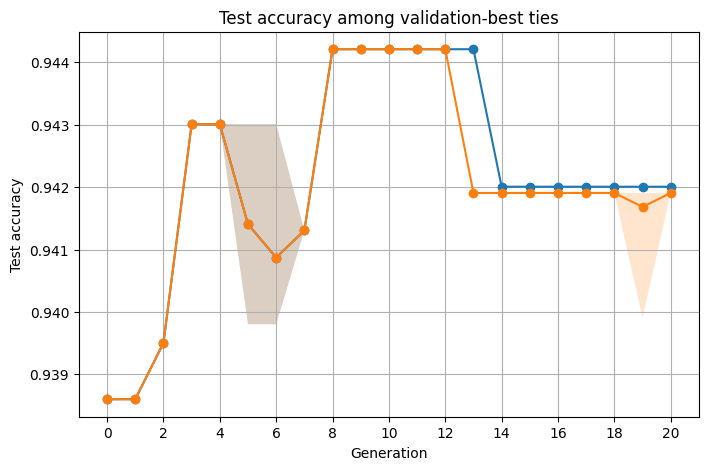

In [95]:
plt.figure(figsize=(8, 5))

x = hist["generation"]
x2 = hist2["generation"]

plt.plot(
    x,
    hist["tied_test_mean"],
    marker="o",
    label="Mean test of validation ties - van + gui"
)

plt.fill_between(
    x,
    hist["tied_test_min"],
    hist["tied_test_max"],
    alpha=0.2,
    label="Test range among validation ties - van + gui"
)

plt.plot(
    x2,
    hist2["tied_test_mean"],
    marker="o",
    label="Mean test of validation ties - full van"
)

plt.fill_between(
    x2,
    hist2["tied_test_min"],
    hist2["tied_test_max"],
    alpha=0.2,
    label="Test range among validation ties - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Test accuracy")
plt.title("Test accuracy among validation-best ties")
# plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

In [96]:
df = pd.DataFrame(sv.data)
df2 = pd.DataFrame(fv.data)

population_stats = (
    df.groupby("generation")["validation_accuracy"]
      .agg(["mean", "median", "min", "max"])
      .reset_index()
)

population_stats2 = (
    df2.groupby("generation")["validation_accuracy"]
      .agg(["mean", "median", "min", "max"])
      .reset_index()
)

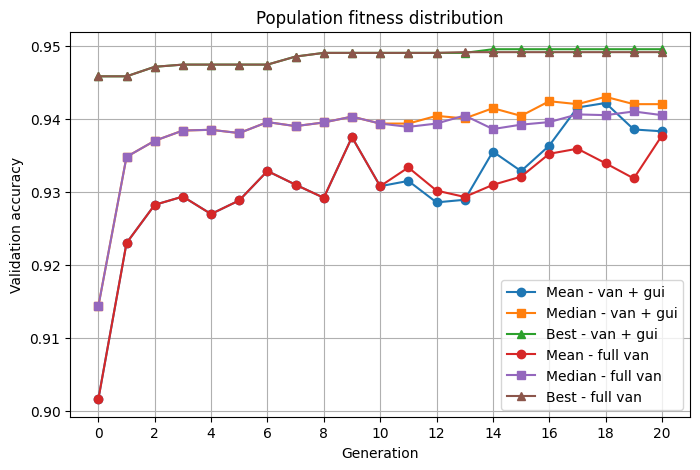

In [97]:
plt.figure(figsize=(8, 5))

plt.plot(
    population_stats["generation"],
    population_stats["mean"],
    marker="o",
    label="Mean - van + gui"
)

plt.plot(
    population_stats["generation"],
    population_stats["median"],
    marker="s",
    label="Median - van + gui"
)

plt.plot(
    population_stats["generation"],
    population_stats["max"],
    marker="^",
    label="Best - van + gui"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["mean"],
    marker="o",
    label="Mean - full van"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["median"],
    marker="s",
    label="Median - full van"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["max"],
    marker="^",
    label="Best - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Validation accuracy")
plt.title("Population fitness distribution")
plt.legend()
plt.grid(True)
plt.show()

In [98]:
def genome_signature(rep):
    return (
        rep["code"],
        tuple(rep["operations"])
    )

In [99]:
df["signature"] = df["representation"].apply(genome_signature)
df2["signature"] = df2["representation"].apply(genome_signature)

diversity = (
    df.groupby("generation")["signature"]
      .nunique()
      .reset_index(name="unique_architectures")
)

diversity2 = (
    df2.groupby("generation")["signature"]
      .nunique()
      .reset_index(name="unique_architectures")
)

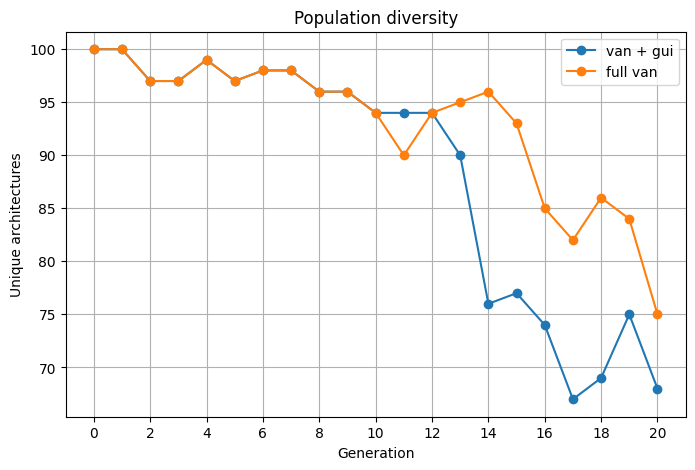

In [100]:
plt.figure(figsize=(8, 5))

plt.plot(
    diversity["generation"],
    diversity["unique_architectures"],
    marker="o"
)

plt.plot(
    diversity2["generation"],
    diversity2["unique_architectures"],
    marker="o"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Unique architectures")
plt.title("Population diversity")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

# seed loop

In [6]:
def loopy_loop(n_runs, size, loops):
    fv_seed = []
    sv_seed = []
    seeds = []

    for run in range(n_runs):
        s = secrets.randbits(32)
        seeds.append(s)

        print(f"Running {run + 1}/{n_runs} | seed = {s}")

        nb101.set_seed(s)
        com_pop = nbcore.Population(size, space, evaluator)
        com_pop.initialize()
        # van = com_pop.copy()
        # gui = com_pop.copy()

        # fv = vanilla_run(loops, van)
        # sv = guided_run(loops, gui)

        fv, sv = compare_run(com_pop, loops=loops)
        
        fv_seed.append(fv)
        sv_seed.append(sv)

    return fv_seed, sv_seed, seeds

In [7]:
runs = 30
pop = 100
evo = 20
fv, sv, seeds = loopy_loop(runs, pop, evo)
# fv, sv, seeds = loopy_loop(20, pop_size * 2, 50)

Running 1/30 | seed = 4168145701
Best performance: 0.9433093070983887
Recording generation 0
Finished recording
Common half
Generation 1 - Best performance: 0.9474158883094788
Recording generation 1
Finished recording
Generation 2 - Best performance: 0.9474158883094788
Recording generation 2
Finished recording
Generation 3 - Best performance: 0.9474158883094788
Recording generation 3
Finished recording
Generation 4 - Best performance: 0.9474158883094788
Recording generation 4
Finished recording
Generation 5 - Best performance: 0.9486178159713745
Recording generation 5
Finished recording
Generation 6 - Best performance: 0.9486178159713745
Recording generation 6
Finished recording
Generation 7 - Best performance: 0.9495192170143127
Recording generation 7
Finished recording
Generation 8 - Best performance: 0.9495192170143127
Recording generation 8
Finished recording
Generation 9 - Best performance: 0.9495192170143127
Recording generation 9
Finished recording
Generation 10 - Best performan

KeyboardInterrupt: 

In [ ]:
def make_history_df(runs, seeds, method):
    rows = []

    for pop, seed in zip(runs, seeds):
        for h in pop.best_history:
            rows.append({
                "seed": seed,
                "method": method,
                "generation": h["generation"],
                "best_val": h["best_val"],
                "best_so_far": h["best_so_far"],
                "best_test": h["best_test"],
                "tied_test_min": h["tied_test_min"],
                "tied_test_max": h["tied_test_max"],
                "tied_test_mean": h["tied_test_mean"],
                "num_tied": h["num_tied"],
            })

    return pd.DataFrame(rows)

In [ ]:
vanilla_df = make_history_df(fv,seeds,"Vanilla")
guided_df = make_history_df(sv,seeds,"Guided")

history_df = pd.concat([vanilla_df, guided_df],ignore_index=True)

In [ ]:
import numpy as np

def summarize(df):
    summary = (
        df.groupby(["method", "generation"])["best_so_far"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    summary["sem"] = (
        summary["std"] /
        np.sqrt(summary["count"])
    )

    summary["ci95"] = 1.96 * summary["sem"]

    return summary

In [ ]:
ticks = range(0, evo + 1, 2)

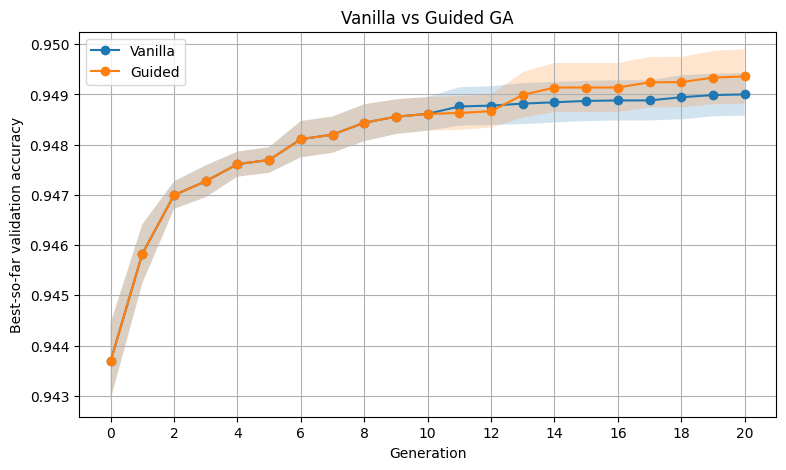

In [ ]:
summary = summarize(history_df)

plt.figure(figsize=(9, 5))

for method in ["Vanilla", "Guided"]:
    d = summary[summary["method"] == method]

    plt.plot(
        d["generation"],
        d["mean"],
        marker="o",
        label=method
    )

    plt.fill_between(
        d["generation"],
        d["mean"] - d["ci95"],
        d["mean"] + d["ci95"],
        alpha=0.2
    )

plt.xticks(ticks)
plt.xlabel("Generation")
plt.ylabel("Best-so-far validation accuracy")
plt.title("Vanilla vs Guided GA")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def final_results(df):
    final = (
        df.sort_values("generation")
        .groupby(["seed", "method"])
        .tail(1)
    )

    return final

In [ ]:
final = final_results(history_df)

pivot = final.pivot(
    index="seed",
    columns="method",
    values="best_so_far"
)

pivot["improvement"] = (
    pivot["Guided"] - pivot["Vanilla"]
)

print(pivot)

method        Guided   Vanilla  improvement
seed                                       
38713123    0.951823  0.951823     0.000000
310502029   0.951823  0.949519     0.002304
349232289   0.949519  0.948518     0.001002
352207228   0.948117  0.948117     0.000000
817117160   0.949018  0.949018     0.000000
825931768   0.951823  0.949920     0.001903
935869483   0.948117  0.948117     0.000000
938895303   0.949519  0.951823    -0.002304
1081627275  0.949519  0.948918     0.000601
1114527601  0.947216  0.947216     0.000000
1137603759  0.951823  0.949519     0.002304
1166282295  0.949519  0.949519     0.000000
1768525185  0.948518  0.949519    -0.001002
1945630958  0.948117  0.948117     0.000000
1995777052  0.949018  0.949018     0.000000
2796783889  0.951823  0.948518     0.003305
2972832763  0.950220  0.951823    -0.001603
2976124885  0.949119  0.949119     0.000000
3083253938  0.948918  0.948918     0.000000
3138841880  0.947216  0.947216     0.000000
3277750715  0.948618  0.948618  

In [ ]:
pivot["good"] = (pivot["improvement"] >= 0).astype(int)
pivot["good"].value_counts()

1    26
0     4
Name: good, dtype: int64

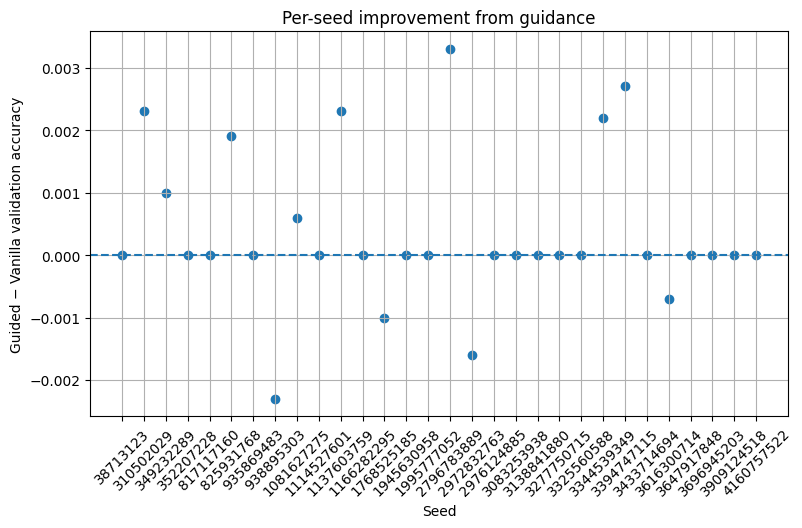

In [ ]:
plt.figure(figsize=(9, 5))

x = np.arange(len(pivot))

plt.axhline(
    0,
    linestyle="--"
)

plt.scatter(
    x,
    pivot["improvement"]
)

plt.xticks(
    x,
    [str(s) for s in pivot.index],
    rotation=45
)

plt.xlabel("Seed")
plt.ylabel("Guided − Vanilla validation accuracy")
plt.title("Per-seed improvement from guidance")
plt.grid(True)
plt.show()

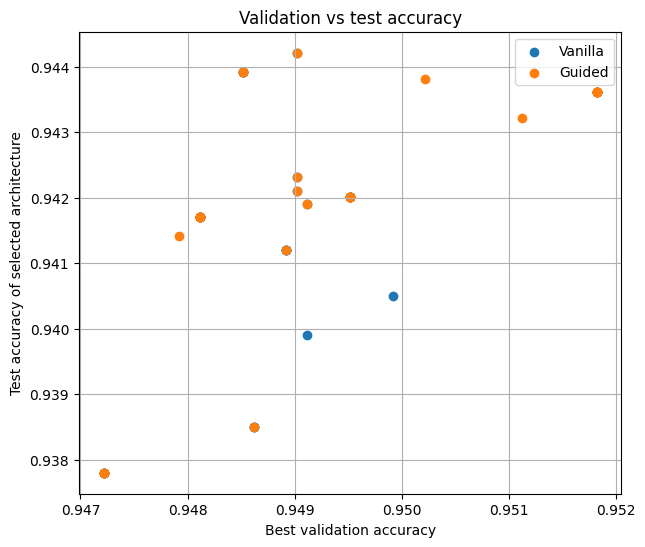

In [ ]:
final_val = final.copy()

plt.figure(figsize=(7, 6))

for method in ["Vanilla", "Guided"]:
    d = final_val[final_val["method"] == method]

    plt.scatter(
        d["best_so_far"],
        d["best_test"],
        label=method
    )

plt.xlabel("Best validation accuracy")
plt.ylabel("Test accuracy of selected architecture")
plt.title("Validation vs test accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
final_val["val_test_gap"] = (
    final_val["best_so_far"]
    - final_val["best_test"]
)

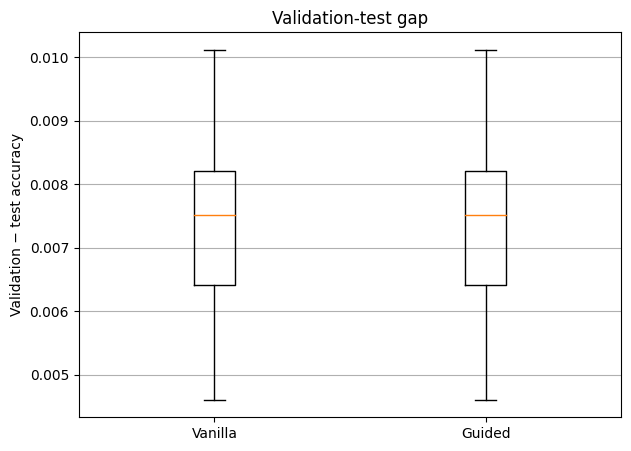

In [ ]:
plt.figure(figsize=(7, 5))

groups = [
    final_val[
        final_val["method"] == "Vanilla"
    ]["val_test_gap"],

    final_val[
        final_val["method"] == "Guided"
    ]["val_test_gap"]
]

plt.boxplot(
    groups,
    labels=["Vanilla", "Guided"]
)

plt.ylabel("Validation − test accuracy")
plt.title("Validation-test gap")
plt.grid(True, axis="y")
plt.show()

# Perm vs df imp

rp perm:

loop 1: outclasses

loop 2: outclasses

loop 3: balanced

loop 4: outclasses

loop 5: slightly higher

rp df imp:

loop 1: outclasses

loop 2: balanced

loop 3: outclasses

loop 4: outclasses

loop 5: outclassed